# EduPredict AI — Análisis exploratorio, limpieza y modelado
**ACA N.º 1 · Aprendizaje Automático · Especialización en Inteligencia Artificial (CUN)**

Este notebook documenta el análisis exploratorio (EDA), la limpieza y el protocolo de modelado del proyecto.
Utiliza **los mismos módulos** de `src/` que el pipeline de entrenamiento y la aplicación Streamlit, de modo que
no existe una diferencia silenciosa entre la limpieza del notebook y la del modelo desplegado.

> Los modelos **no** se reentrenan aquí: el entrenamiento oficial se ejecuta con `python -m src.train` y este
> notebook lee las métricas reales guardadas en `models/`. Para reentrenar desde el notebook, ejecute la celda
> opcional de la sección 7.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import data_dictionary as dd
from src.data_loader import load_raw, clean_dataset, consistency_report, decode_for_display

sns.set_theme(style="whitegrid")
PALETTE = {dd.CLASS_LABELS_ES[c]: dd.CLASS_COLORS[c] for c in dd.CLASSES}
ORDER = [dd.CLASS_LABELS_ES[c] for c in dd.CLASSES]
pd.set_option("display.max_columns", 50)

## 1. Exploración general del dataset
Dataset oficial **Predict Students' Dropout and Academic Success** (UCI, ID 697). El CSV usa `;` como separador
y codificación UTF-8 con BOM.

In [2]:
raw = load_raw(ROOT / "data" / "data.csv")
print("Forma:", raw.shape)
print("Nombres de columna problemáticos:", [repr(c) for c in raw.columns if c != c.strip() or "\t" in c])
raw.head()

Forma: (4424, 37)
Nombres de columna problemáticos: ["'Daytime/evening attendance\\t'"]


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


Se observa que la columna `Daytime/evening attendance` trae un **tabulador** al final del nombre. Un
`df["Daytime/evening attendance"]` fallaría silenciosamente en otro código; por eso la limpieza normaliza los
nombres y los convierte a identificadores internos `snake_case`.

## 2. Limpieza determinista y tipos de variables

In [3]:
df = clean_dataset(raw)
types = pd.DataFrame({
    "variable": dd.ALL_FEATURES,
    "descripción": [dd.label(c) for c in dd.ALL_FEATURES],
    "tipo": ["Nominal" if c in dd.NOMINAL_FEATURES else "Binaria" if c in dd.BINARY_FEATURES else "Numérica" for c in dd.ALL_FEATURES],
    "unidad": [dd.FEATURE_INFO[c][1] for c in dd.ALL_FEATURES],
    "valores_únicos": [df[c].nunique() for c in dd.ALL_FEATURES],
})
types

,variable,descripción,tipo,unidad,valores_únicos
0,marital_status,Estado civil,Nominal,código,6
1,application_mode,Modalidad de admisión,Nominal,código,18
2,course,Programa académico,Nominal,código,17
3,previous_qualification,Formación previa,Nominal,código,17
4,nationality,Nacionalidad,Nominal,código,21
5,mother_qualification,Nivel educativo de la madre,Nominal,código,29
6,father_qualification,Nivel educativo del padre,Nominal,código,34
7,mother_occupation,Ocupación de la madre,Nominal,código,32
8,father_occupation,Ocupación del padre,Nominal,código,46
9,daytime_attendance,Jornada,Binaria,"1 = diurna, 0 = nocturna",2


**Decisión metodológica:** variables como `course`, `application_mode` u `occupation` están almacenadas como
enteros, pero son **códigos nominales** (p. ej. 9500 = Enfermería). Tratarlas como numéricas impondría un orden y
distancias inexistentes, especialmente en la regresión logística. Por ello se codifican con One-Hot (o como
categóricas nativas en HistGradientBoosting).

## 3. Estadísticas descriptivas, nulos y duplicados

In [4]:
print("Nulos totales:", int(df.isna().sum().sum()))
print("Filas duplicadas:", int(df.duplicated().sum()))
df[dd.NUMERIC_FEATURES].describe().T.round(2)

Nulos totales: 0
Filas duplicadas: 0


,count,mean,std,min,25%,50%,75%,max
application_order,4424.0,1.73,1.31,0.00,1.00,1.00,2.00,9.00
previous_qualification_grade,4424.0,132.61,13.19,95.00,125.00,133.10,140.00,190.00
admission_grade,4424.0,126.98,14.48,95.00,117.90,126.10,134.80,190.00
age_at_enrollment,4424.0,23.27,7.59,17.00,19.00,20.00,25.00,70.00
cu_1st_credited,4424.0,0.71,2.36,0.00,0.00,0.00,0.00,20.00
cu_1st_enrolled,4424.0,6.27,2.48,0.00,5.00,6.00,7.00,26.00
cu_1st_evaluations,4424.0,8.30,4.18,0.00,6.00,8.00,10.00,45.00
cu_1st_approved,4424.0,4.71,3.09,0.00,3.00,5.00,6.00,26.00
cu_1st_grade,4424.0,10.64,4.84,0.00,11.00,12.29,13.40,18.88
cu_1st_without_eval,4424.0,0.14,0.69,0.00,0.00,0.00,0.00,12.00


## 4. Distribución de la variable objetivo

,n,%
target,,
Deserción,1421,32.1
Matriculado,794,17.9
Graduado,2209,49.9


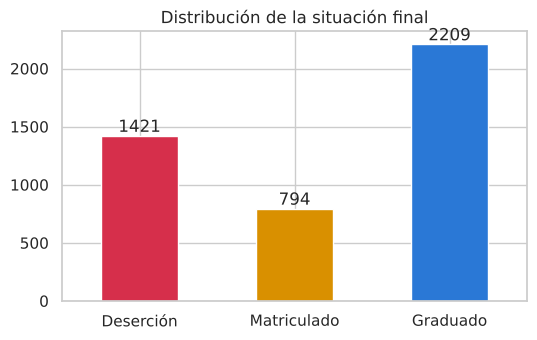

In [5]:
dist = df[dd.TARGET].map(dd.CLASS_LABELS_ES).value_counts().reindex(ORDER)
display(pd.DataFrame({"n": dist, "%": (dist / dist.sum() * 100).round(1)}))
ax = dist.plot.bar(color=[PALETTE[c] for c in ORDER], figsize=(6, 3.5), rot=0)
ax.bar_label(ax.containers[0]); ax.set_title("Distribución de la situación final"); ax.set_xlabel(""); plt.show()

El dataset está **desbalanceado** (≈50 % Graduado, 32 % Deserción, 18 % Matriculado). Consecuencias:
* La *accuracy* sola es engañosa; se reportan **macro-F1** y **balanced accuracy**.
* La división 80/20 y la validación cruzada son **estratificadas**.
* El uso de pesos de clase (`class_weight`) se incluye como hiperparámetro y lo decide la validación cruzada.

## 5. Histogramas y boxplots

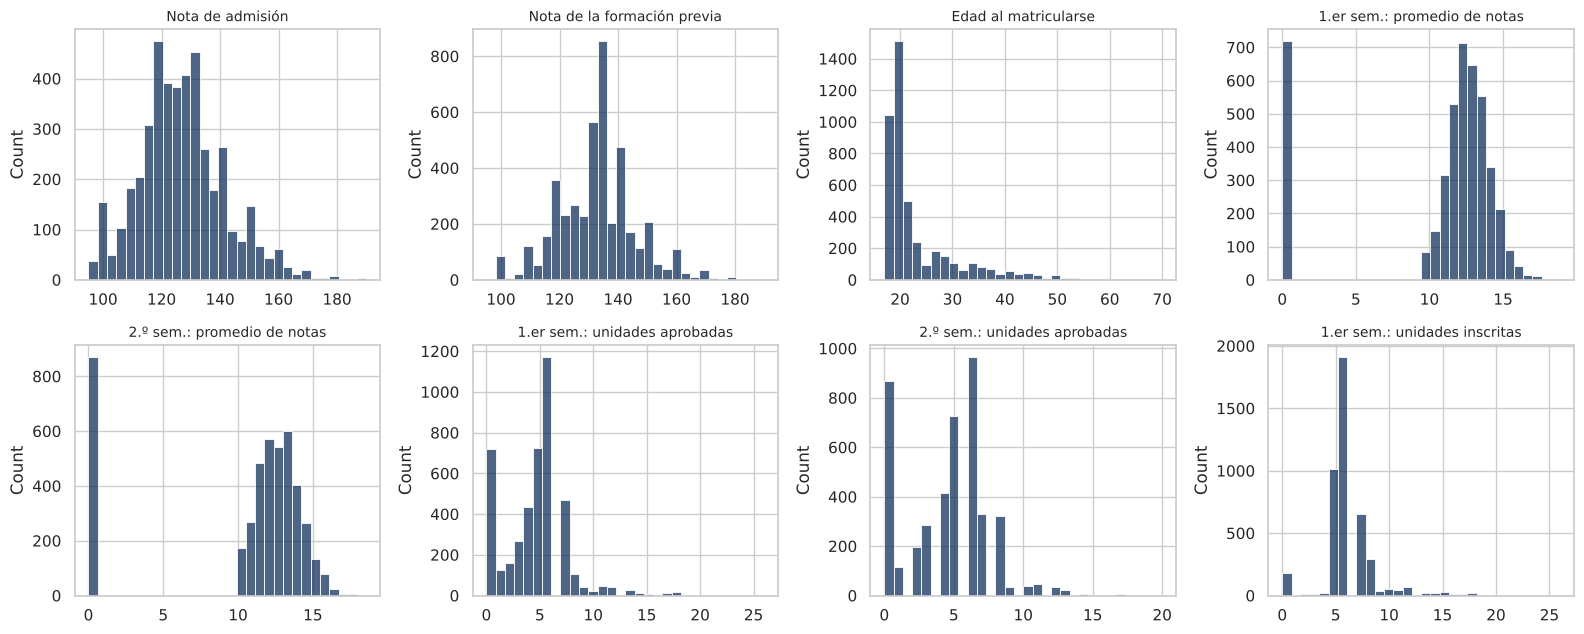

In [6]:
cols = ["admission_grade", "previous_qualification_grade", "age_at_enrollment",
        "cu_1st_grade", "cu_2nd_grade", "cu_1st_approved", "cu_2nd_approved", "cu_1st_enrolled"]
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for ax, c in zip(axes.flat, cols):
    sns.histplot(df[c], bins=30, ax=ax, color="#13315C"); ax.set_title(dd.label(c), fontsize=10); ax.set_xlabel("")
plt.tight_layout(); plt.show()

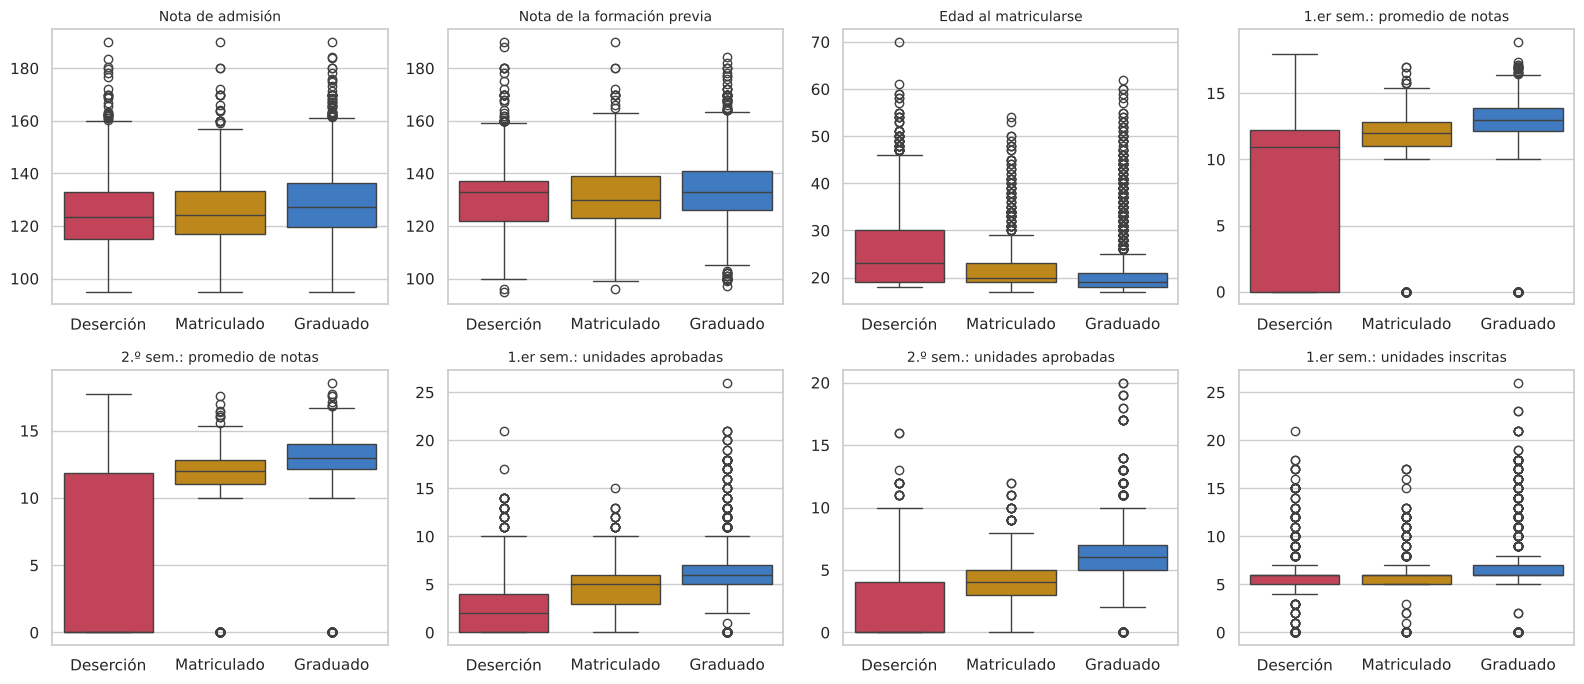

In [7]:
disp = decode_for_display(df)
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.flat, cols):
    sns.boxplot(data=disp, x="clase", y=c, order=ORDER, hue="clase", palette=PALETTE, ax=ax, legend=False)
    ax.set_title(dd.label(c), fontsize=10); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

**Observaciones:**
* Las notas semestrales presentan una masa importante en **0**: corresponde a estudiantes sin unidades aprobadas
  (no a datos faltantes). Esta situación se concentra en la clase *Deserción*.
* Las unidades aprobadas y las notas del 1.er y 2.º semestre separan con claridad *Graduado* de *Deserción*;
  *Matriculado* queda en una zona intermedia, lo que anticipa que será la clase más difícil.
* La edad al matricularse es asimétrica a la derecha; los estudiantes mayores tienden a desertar más.

## 6. Outliers y consistencia de los datos

In [8]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())
out = pd.DataFrame({"outliers_IQR": {c: iqr_outliers(df[c]) for c in dd.NUMERIC_FEATURES}})
out["%"] = (out["outliers_IQR"] / len(df) * 100).round(1)
out.sort_values("outliers_IQR", ascending=False).head(12)

,outliers_IQR,%
cu_2nd_grade,877,19.8
cu_1st_grade,726,16.4
cu_1st_credited,577,13.0
application_order,541,12.2
cu_2nd_credited,530,12.0
age_at_enrollment,441,10.0
cu_1st_enrolled,424,9.6
cu_2nd_enrolled,369,8.3
cu_1st_without_eval,294,6.6
cu_2nd_without_eval,282,6.4


In [9]:
rep = consistency_report(df)
print(json.dumps(rep, indent=2, ensure_ascii=False))
print("\nDistribución de clase en estudiantes con 0 unidades inscritas en el 1.er semestre:")
print(df.loc[df.cu_1st_enrolled == 0, dd.TARGET].value_counts())

{
  "filas": 4424,
  "columnas_predictoras": 36,
  "nulos_totales": 0,
  "duplicados": 0,
  "fuera_de_rango": {},
  "reglas": {
    "aprobadas_mayor_inscritas_1st": 0,
    "nota_positiva_sin_aprobadas_1st": 0,
    "sin_inscripcion_1st": 180,
    "aprobadas_mayor_inscritas_2nd": 0,
    "nota_positiva_sin_aprobadas_2nd": 0,
    "sin_inscripcion_2nd": 180
  },
  "clases_no_validas": 0
}

Distribución de clase en estudiantes con 0 unidades inscritas en el 1.er semestre:
target
Dropout     77
Graduate    75
Enrolled    28
Name: count, dtype: int64


**Decisión sobre valores extremos:** **no se eliminan**.
* Todos los valores están dentro de los rangos documentados por UCI (notas 0–20, notas de admisión 0–200, etc.).
* Edades altas (hasta 70) son legítimas: existe una vía de admisión para **mayores de 23 años**.
* Los 180 estudiantes con 0 unidades inscritas son casos reales (p. ej. convalidaciones completas o abandono
  temprano); eliminarlos sesgaría la muestra de la clase *Deserción*.
* Las reglas lógicas se cumplen: nunca hay más unidades aprobadas que inscritas, y no hay notas positivas sin
  unidades aprobadas.
* Los modelos basados en árboles son robustos a extremos; para la regresión logística se estandarizan las numéricas
  dentro del pipeline (ajustado solo con datos de entrenamiento).

## 7. Correlaciones de variables numéricas

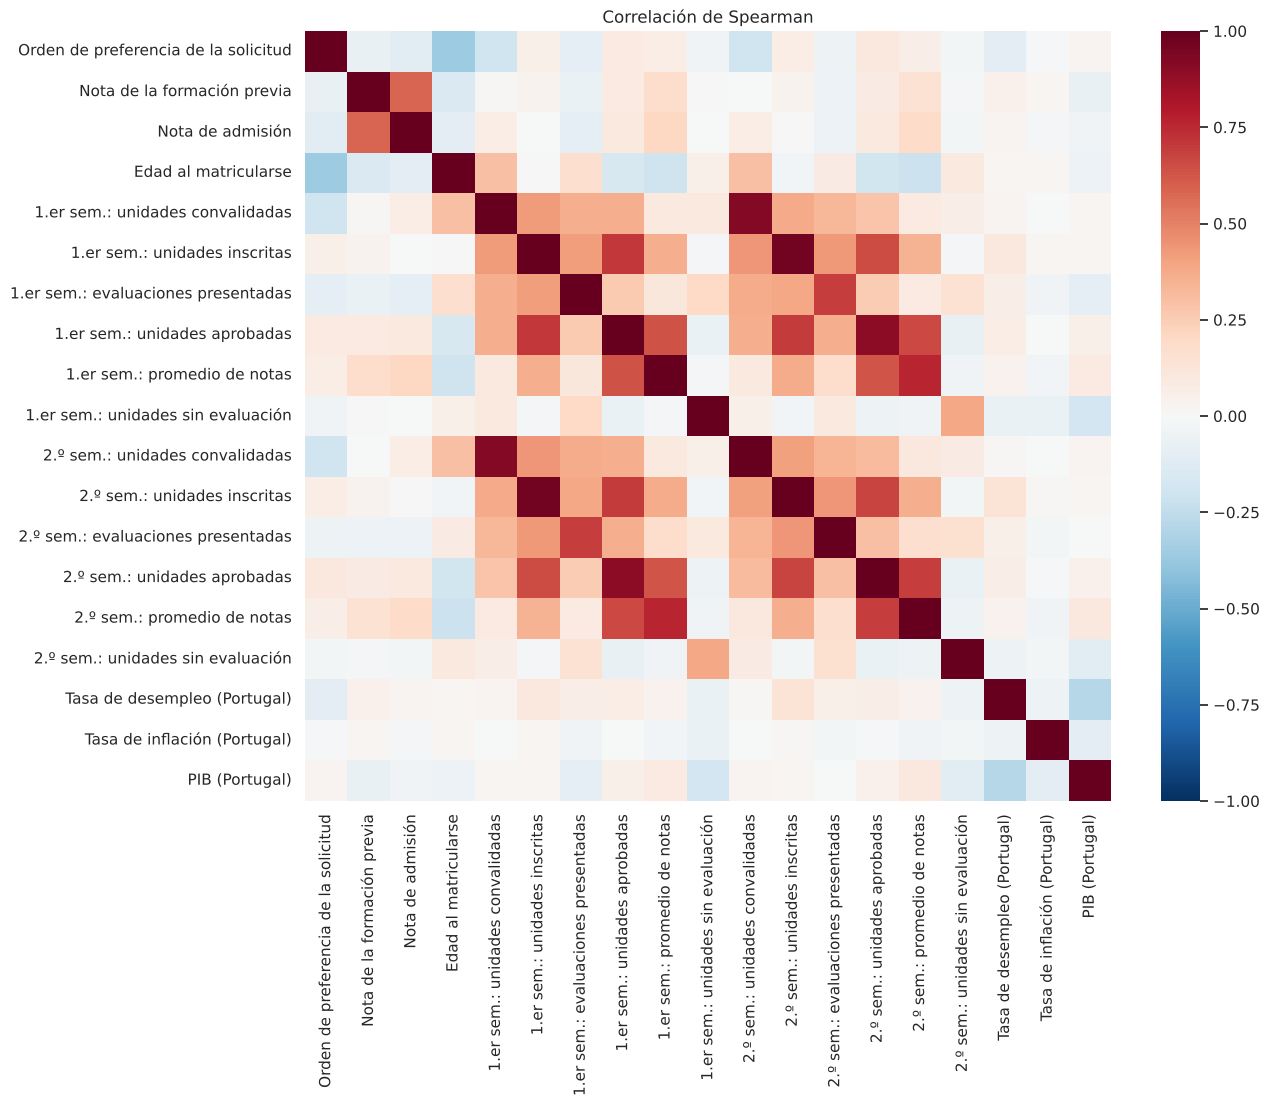

cu_1st_enrolled     cu_2nd_enrolled       0.962
cu_1st_credited     cu_2nd_credited       0.914
cu_1st_approved     cu_2nd_approved       0.892
cu_1st_grade        cu_2nd_grade          0.762
cu_1st_enrolled     cu_1st_approved       0.707
cu_1st_approved     cu_2nd_enrolled       0.699
cu_2nd_approved     cu_2nd_grade          0.694
cu_1st_evaluations  cu_2nd_evaluations    0.694
cu_2nd_enrolled     cu_2nd_approved       0.674
cu_1st_approved     cu_2nd_grade          0.663
dtype: float64

In [10]:
corr = df[dd.NUMERIC_FEATURES].corr(method="spearman")
plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, xticklabels=[dd.label(c) for c in corr], yticklabels=[dd.label(c) for c in corr])
plt.title("Correlación de Spearman"); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack().sort_values(key=abs, ascending=False)
pairs.head(10).round(3)

Las variables de **1.er y 2.º semestre están muy correlacionadas** (inscritas, evaluaciones, aprobadas).
La multicolinealidad no afecta la capacidad predictiva de los árboles, pero sí la interpretación de coeficientes
de la regresión logística, que se regulariza (parámetro `C`).

## 8. Variables relacionadas con la deserción

In [11]:
rows = []
for c in dd.BINARY_FEATURES:
    for v in (0, 1):
        sub = df[df[c] == v]
        rows.append({"variable": dd.label(c), "valor": dd.code_label(c, v), "n": len(sub),
                     "tasa_deserción_%": round((sub[dd.TARGET] == "Dropout").mean() * 100, 1)})
pd.DataFrame(rows)

,variable,valor,n,tasa_deserción_%
0,Jornada,Nocturna,483,42.9
1,Jornada,Diurna,3941,30.8
2,Estudiante desplazado de su residencia,No,1998,37.6
3,Estudiante desplazado de su residencia,Sí,2426,27.6
4,Necesidades educativas especiales,No,4373,32.1
5,Necesidades educativas especiales,Sí,51,33.3
6,Tiene deudas con la institución,No,3921,28.3
7,Tiene deudas con la institución,Sí,503,62.0
8,Matrícula al día,No,528,86.6
9,Matrícula al día,Sí,3896,24.7


In [12]:
tmp = df.assign(dropout=(df[dd.TARGET] == "Dropout").astype(int))
num_assoc = tmp[dd.NUMERIC_FEATURES + ["dropout"]].corr(method="spearman")["dropout"].drop("dropout")
num_assoc.rename(dd.label).sort_values(key=abs, ascending=False).round(3).head(12)

2.º sem.: unidades aprobadas           -0.582
1.er sem.: unidades aprobadas          -0.523
2.º sem.: promedio de notas            -0.510
1.er sem.: promedio de notas           -0.443
Edad al matricularse                    0.280
2.º sem.: unidades inscritas           -0.188
1.er sem.: unidades inscritas          -0.180
2.º sem.: evaluaciones presentadas     -0.119
Nota de admisión                       -0.099
Orden de preferencia de la solicitud   -0.083
Nota de la formación previa            -0.080
2.º sem.: unidades sin evaluación       0.066
Name: dropout, dtype: float64

In [13]:
by_course = (df.groupby("course")[dd.TARGET].agg(n="size", tasa=lambda s: (s == "Dropout").mean() * 100)
             .rename(index=lambda c: dd.code_label("course", c)).sort_values("tasa", ascending=False).round(1))
by_course

,n,tasa
course,,
Tecnologías de Producción de Biocombustibles,12,66.7
Equinocultura,141,55.3
Ingeniería Informática,170,54.1
Gestión (nocturno),268,50.7
Educación Básica,192,44.3
Agronomía,210,41.0
Higiene Oral,86,38.4
Diseño de Animación y Multimedia,215,38.1
Turismo,252,38.1


**Hallazgos principales** (asociaciones descriptivas, no causales):
* **Matrícula al día** y **deudas con la institución** son los indicadores administrativos más asociados con la
  deserción.
* Los **becarios** desertan bastante menos que los no becarios.
* El **rendimiento académico** (unidades aprobadas y notas, en especial del 2.º semestre) es el factor más fuertemente
  asociado.
* La tasa varía mucho entre programas; algunos tienen muy pocos estudiantes (p. ej. Biocombustibles, n = 12), por lo
  que su tasa es poco estable.

## 9. Protocolo de modelado
1. División **estratificada 80/20**, `random_state=42`. El conjunto de prueba se aparta.
2. Para cada algoritmo, un `Pipeline` = ingeniería de variables sin estado (tasa de aprobación por semestre) +
   `ColumnTransformer` específico + clasificador:

| Algoritmo | Nominales | Numéricas | Desbalance (en la rejilla) |
|---|---|---|---|
| Regresión Logística | One-Hot (categorías con < 10 casos agrupadas) | StandardScaler | `class_weight` ∈ {None, balanced} |
| Random Forest | One-Hot | sin escalar | `class_weight` ∈ {None, balanced_subsample} |
| HistGradientBoosting | Ordinal + categóricas nativas | sin escalar | `class_weight` ∈ {None, balanced} |

3. `GridSearchCV` con `StratifiedKFold(5, shuffle=True, random_state=42)` sobre el 80 % de entrenamiento, optimizando
   **macro-F1** (refit). Al estar el preprocesamiento dentro del pipeline, el escalado y la codificación se ajustan
   **solo con los pliegues de entrenamiento** de cada iteración: no hay fuga de información.
4. El modelo final se elige por **macro-F1 medio de validación cruzada**. El conjunto de prueba se usa una sola vez
   para reportar el desempeño final de los tres modelos.
5. **Alerta temprana:** se repite todo el protocolo con un segundo conjunto de columnas que excluye las 6 variables del
   2.º semestre, generando un artefacto independiente (`models/modelo_temprano.joblib`).

In [14]:
from src.preprocessing import FULL, EARLY
print("Columnas modelo completo:", len(FULL.raw_columns), "+ derivadas", FULL.engineered)
print("Columnas alerta temprana:", len(EARLY.raw_columns), "+ derivadas", EARLY.engineered)
print("Excluidas en alerta temprana:", sorted(set(FULL.raw_columns) - set(EARLY.raw_columns)))

Columnas modelo completo: 36 + derivadas ['cu_1st_approval_rate', 'cu_2nd_approval_rate']
Columnas alerta temprana: 30 + derivadas ['cu_1st_approval_rate']
Excluidas en alerta temprana: ['cu_2nd_approved', 'cu_2nd_credited', 'cu_2nd_enrolled', 'cu_2nd_evaluations', 'cu_2nd_grade', 'cu_2nd_without_eval']


In [15]:
# Opcional: reentrenar desde el notebook (≈3 min con 4 núcleos). Por defecto se usan los artefactos ya generados.
RETRAIN = False
if RETRAIN:
    from src.train import main
    main([])

## 10. Resultados reales (leídos de `models/metricas*.json`)

In [16]:
def tabla(mod):
    m = json.loads((ROOT / "models" / ("metricas.json" if mod == "completo" else "metricas_temprano.json")).read_text(encoding="utf-8"))
    rows = []
    for k, v in m["modelos"].items():
        rows.append({"modelo": v["nombre"], "seleccionado": "★" if k == m["modelo_seleccionado"] else "",
                     "CV macro-F1": f'{v["cv"]["f1_macro"]["media"]:.4f} ± {v["cv"]["f1_macro"]["desv"]:.4f}',
                     "CV balanced acc.": round(v["cv"]["balanced_accuracy"]["media"], 4),
                     "Test accuracy": round(v["prueba"]["accuracy"], 4), "Test macro-F1": round(v["prueba"]["f1_macro"], 4),
                     "Test balanced acc.": round(v["prueba"]["balanced_accuracy"], 4),
                     **{f"Recall {dd.CLASS_LABELS_ES[c]}": round(v["prueba"]["por_clase"][c]["recall"], 3) for c in dd.CLASSES}})
    return m, pd.DataFrame(rows)
m_full, t_full = tabla("completo"); t_full

,modelo,seleccionado,CV macro-F1,CV balanced acc.,Test accuracy,Test macro-F1,Test balanced acc.,Recall Deserción,Recall Matriculado,Recall Graduado
0,Regresión Logística,,0.7169 ± 0.0143,0.7243,0.7277,0.6877,0.6981,0.690,0.610,0.794
1,Random Forest,,0.7255 ± 0.0170,0.7229,0.7672,0.7164,0.7157,0.729,0.547,0.871
2,Gradient Boosting (HistGradientBoosting),★,0.7282 ± 0.0158,0.7318,0.7458,0.7054,0.7154,0.711,0.623,0.812


In [17]:
w = m_full["modelo_seleccionado"]
print("Modelo seleccionado:", m_full["modelos"][w]["nombre"])
print("Hiperparámetros:", m_full["modelos"][w]["mejores_hiperparametros"])
pd.DataFrame(m_full["modelos"][w]["prueba"]["por_clase"]).T.rename(index=dd.CLASS_LABELS_ES).round(3)

Modelo seleccionado: Gradient Boosting (HistGradientBoosting)
Hiperparámetros: {'class_weight': 'balanced', 'l2_regularization': 1.0, 'learning_rate': 0.05, 'max_leaf_nodes': 15}


,precision,recall,f1,soporte
Deserción,0.815,0.711,0.759,284.0
Matriculado,0.442,0.623,0.517,159.0
Graduado,0.869,0.812,0.840,442.0


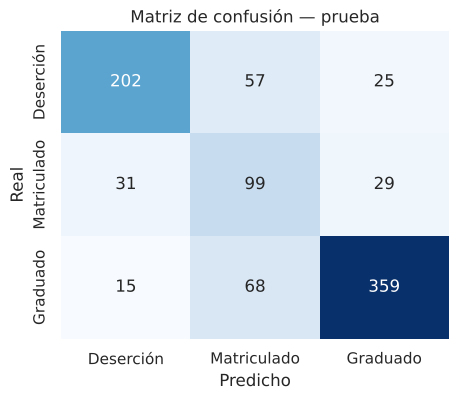

In [18]:
cm = m_full["modelos"][w]["prueba"]["matriz_confusion"]
lbl = [dd.CLASS_LABELS_ES[c] for c in cm["etiquetas"]]
plt.figure(figsize=(5, 4))
sns.heatmap(pd.DataFrame(cm["valores"], index=lbl, columns=lbl), annot=True, fmt="d", cmap="Blues", cbar=False)
plt.ylabel("Real"); plt.xlabel("Predicho"); plt.title("Matriz de confusión — prueba"); plt.show()

In [19]:
pd.DataFrame(m_full["importancia_permutacion_prueba"])[["etiqueta", "importancia_media", "importancia_desv"]].round(4)

,etiqueta,importancia_media,importancia_desv
0,2.º sem.: unidades aprobadas,0.2124,0.0123
1,1.er sem.: unidades aprobadas,0.0666,0.0061
2,Matrícula al día,0.0542,0.0052
3,2.º sem.: unidades inscritas,0.0457,0.0071
4,Programa académico,0.0279,0.0068
5,1.er sem.: unidades inscritas,0.0184,0.0068
6,Ocupación del padre,0.0146,0.0059
7,Edad al matricularse,0.0125,0.0042
8,Ocupación de la madre,0.0089,0.0027
9,2.º sem.: promedio de notas,0.0086,0.0055


### Modelo de alerta temprana (información hasta el cierre del 1.er semestre)

In [20]:
m_early, t_early = tabla("temprano"); t_early

,modelo,seleccionado,CV macro-F1,CV balanced acc.,Test accuracy,Test macro-F1,Test balanced acc.,Recall Deserción,Recall Matriculado,Recall Graduado
0,Regresión Logística,,0.6844 ± 0.0167,0.6911,0.7096,0.6715,0.6813,0.673,0.597,0.774
1,Random Forest,,0.6932 ± 0.0230,0.6897,0.7333,0.6777,0.6786,0.697,0.497,0.842
2,Gradient Boosting (HistGradientBoosting),★,0.6976 ± 0.0117,0.6975,0.7198,0.6747,0.6810,0.715,0.541,0.787


## 11. Conclusiones
* Los tres algoritmos alcanzan desempeños cercanos; el ganador por validación cruzada se exporta como pipeline completo.
  Cuando la diferencia entre modelos es menor que la desviación entre pliegues, debe interpretarse como un empate
  técnico.
* La clase **Matriculado** es la más difícil (recall ≈ 0,5–0,6): su perfil académico es intermedio entre graduados y
  desertores.
* El **rendimiento académico** (unidades aprobadas) y la **situación administrativa** (matrícula al día) son las
  variables de las que más depende el modelo.
* El modelo de **alerta temprana** pierde algo de desempeño al renunciar al 2.º semestre, a cambio de poder
  anticipar la situación un semestre antes. Ambas modalidades responden a preguntas distintas y no se comparan como
  si usaran la misma información.